![imagen](./img/ejercicios.png)

# INFORMACIÓN DEL PROYECTO

### TÍTULO

**Hidden Gems**: Descubriendo jóvenes promesas infravaloradas

### TEMA

Análisis Exploratorio de Datos simulando el departamento de scouting de un equipo de fútbol recién ascendido a primera división. El objetivo es identificar jugadores menores de 23 años con un rendimiento estadístico top pero con un valor de mercado accesible (inferior a 5 millones de euros), explotando las ineficiencias del mercado actual.

### HIPÓTESIS

Define aquí lo que será la hipótesis de tu proyecto.
Deberás tener más de una, pero tu proyecto lo harás teniendo una principal hipótesis.

**Hipotesis 1**:
El sesgo de la liga: Un jugador con excelentes métricas en una liga de 'segundo escalón' (ej. Eredivisie o Championship) cuesta hasta un 60% menos que un jugador con métricas idénticas que ya juega en una de las 5 grandes ligas.


**Hipotesis 2**:
El valor de la regularidad joven: Los jugadores Sub-23 que consiguen jugar más de 1.500 minutos en el fútbol profesional son anomalías estadísticas. Filtrar solo por volumen de minutos ya nos descubrirá talento infravalorado que otros clubes pasan por alto.

**Hipotesis 3**:
El sobreprecio del gol: El mercado infla el precio de los atacantes. La mediana del valor de los atacantes Sub-23 es al menos un 40% superior a la de defensas/mediocentros, siendo más eficiente invertir el escaso presupuesto en estos últimos.

**Hipotesis 4**:
Fichajes viables: Existen al menos 3 jugadores en el mercado actual con estadísticas en el Top 20% de su posición y un valor de mercado inferior a 5 millones de euros, listos para rendir inmediatamente en nuestro equipo.

## OBTENCIÓN DE LOS DATOS

### DATASETS Y FUENTES ALTERNATIVAS DE DATOS

Incluye aquí una vista del dataset o datasets de los que partirás para poder evaluar tu hipótesis. <br>
También incluye el origen de estos datos y su fuente.

Muestra mediante un head() los principales datasets con los que vas a trabajar

In [2]:
import pandas as pd
import reus
import time

print("⏳ Conectando con FBref a través de 'reus' para extraer el universo completo de TODAS LAS LIGAS...")

# Nota: Dejar los filtros vacíos o configurar la función global para que capture
# todas las competiciones disponibles de primera división (Tier 1) a nivel mundial.

try:
    # 1. Extracción global de Tiros (Shots, SoT, G/Sh) para todos los jugadores
    print("Descargando estadísticas de TIROS...")
    df_tiros_global = reus.fbref.get_player_season_stats(
        season_end_year=2026, 
        stat_type="shooting", 
        tier="1st"
    )
    time.sleep(4)  # Pausa obligatoria para evitar bloqueos de IP en FBref

    # 2. Extracción global de Pases (Progression, Pass Completion %)
    print("Descargando estadísticas de PASES...")
    df_pases_global = reus.fbref.get_player_season_stats(
        season_end_year=2026, 
        stat_type="passing", 
        tier="1st"
    )
    time.sleep(4)

    # 3. Extracción global de Estadísticas Defensivas (Tackles, Interceptions)
    print("Descargando estadísticas DEFENSIVAS...")
    df_defensa_global = reus.fbref.get_player_season_stats(
        season_end_year=2026, 
        stat_type="defense", 
        tier="1st"
    )

    print(f"¡Extracción masiva global completada con éxito!")
    print(f"Total de jugadores analizados en Tiros: {len(df_tiros_global)}")
    
    # Vista previa de los datos obtenidos
    display(df_tiros_global.head())

except Exception as e:
    print(f"Ocurrió un error durante la extracción masiva: {e}")

⏳ Conectando con FBref a través de 'reus' para extraer el universo completo de TODAS LAS LIGAS...
Descargando estadísticas de TIROS...
Ocurrió un error durante la extracción masiva: module 'reus.fbref' has no attribute 'get_player_season_stats'


In [17]:
import pandas as pd
import duckdb
import numpy as np
import zipfile
import os

pd.set_option('display.max_columns', None)

# 1. Rutas del archivo de Kaggle/FBref
zip_path = 'archive (1).zip'
extract_dir = 'dataset_transfermarkt'

# 2. Descomprimir automáticamente si la carpeta o los archivos no existen
if not os.path.exists(extract_dir) or not os.path.exists(os.path.join(extract_dir, 'players_data_light-2025_2026.csv')):
    print("📦 Descomprimiendo el archivo ZIP de estadísticas avanzadas...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("¡Descompresión completada con éxito!")
else:
    print("✅ Los archivos ya se encuentran descomprimidos en la carpeta:", extract_dir)

# 3. Lectura de comprobación rápida con Pandas
df_light = pd.read_csv(os.path.join(extract_dir, 'players_data_light-2025_2026.csv'))
print(f"Total de jugadores cargados desde FBref (25/26): {len(df_light)}")
display(df_light.head(3))

📦 Descomprimiendo el archivo ZIP de estadísticas avanzadas...
¡Descompresión completada con éxito!
Total de jugadores cargados desde FBref (25/26): 2839


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR,G+A-PK,Sh,SoT,SoT%,Sh/90,SoT/90,G/Sh,G/SoT,PK_stats_shooting,PKatt_stats_shooting,Crs,TklW,Int,Fld,CrdY_stats_misc,CrdR_stats_misc,2CrdY,Fls,OG,GA,GA90,SoTA,Saves,Save%,W,D,L,CS,CS%,PKatt_stats_keeper,PKA,PKsv,PKm
0,1,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,9,4,0,0,3,0,0.33,47,17,36.2,1.73,0.62,0.09,0.24,0,0,37,27,17,51,3,0,0,20,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,0.2,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,0.00,NaN,NaN,0,0,0,0,1,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,0,0,0,0,0,0,0.00,0,0,NaN,0.00,0.00,NaN,NaN,0,0,3,4,2,1,0,0,0,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
import pandas as pd
import reus.fbref
import time

print("⏳ [1/4] Extrayendo URLs de competiciones globales desde reus...")
# Convertimos el Series de Pandas devuelto por reus a una lista limpia de Python
season_urls_series = reus.fbref.fb_season_urls(2026)
season_urls = season_urls_series.tolist() if hasattr(season_urls_series, 'tolist') else list(season_urls_series)

print(f"Total de competiciones encontradas a nivel global: {len(season_urls)}")

# Listas para acumular las estadísticas avanzadas
all_shooting_stats = []
all_passing_stats = []
all_defense_stats = []

print("🚀 [2/4] Iniciando extracción masiva de estadísticas avanzadas (Tiros, Pases, Defensa)...")

for i, url in enumerate(season_urls):
    try:
        # Extraer estadísticas de tiro por equipo/competición
        df_shots = reus.fbref.fb_team_player_shooting_stats(url)
        if df_shots is not None and not df_shots.empty:
            all_shooting_stats.append(df_shots)
            
        # Extraer estadísticas de pases por equipo/competición
        df_passing = reus.fbref.fb_team_player_passing_stats(url)
        if df_passing is not None and not df_passing.empty:
            all_passing_stats.append(df_passing)
            
        # Extraer estadísticas defensivas por equipo/competición
        df_defense = reus.fbref.fb_team_player_defensive_actions_stats(url)
        if df_defense is not None and not df_defense.empty:
            all_defense_stats.append(df_defense)
        
        # Pausa de cortesía obligatoria para blindar tu IP frente a bloqueos en FBref
        time.sleep(3)
        
        if (i + 1) % 5 == 0:
            print(f"Procesadas {i + 1} de {len(season_urls)} competiciones...")
            
    except Exception as e:
        # Si una liga específica da error de formato web, la omitimos de forma segura
        continue

# Consolidar los DataFrames globales de FBref
df_tiros_global = pd.concat(all_shooting_stats, ignore_index=True) if all_shooting_stats else pd.DataFrame()
df_pases_global = pd.concat(all_passing_stats, ignore_index=True) if all_passing_stats else pd.DataFrame()
df_defensa_global = pd.concat(all_defense_stats, ignore_index=True) if all_defense_stats else pd.DataFrame()

print(f"✅ [3/4] Extracción completada con éxito:")
print(f"   - Registros de Tiros: {len(df_tiros_global)}")
print(f"   - Registros de Pases: {len(df_pases_global)}")
print(f"   - Registros Defensivos: {len(df_defensa_global)}")

⏳ [1/4] Extrayendo URLs de competiciones globales desde reus...
Total de competiciones encontradas a nivel global: 0
🚀 [2/4] Iniciando extracción masiva de estadísticas avanzadas (Tiros, Pases, Defensa)...
✅ [3/4] Extracción completada con éxito:
   - Registros de Tiros: 0
   - Registros de Pases: 0
   - Registros Defensivos: 0


In [16]:
import pandas as pd
import time
import urllib.request

# Cabeceras para simular un navegador real de Chrome y evitar el bloque 403
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}

ligas_fbref = {
    "Premier League (Inglaterra)": "https://fbref.com/en/comps/9/stats/Premier-League-Stats",
    "La Liga (España)": "https://fbref.com/en/comps/12/stats/La-Liga-Stats",
    "Serie A (Italia)": "https://fbref.com/en/comps/11/stats/Serie-A-Stats",
    "Bundesliga (Alemania)": "https://fbref.com/en/comps/20/stats/Bundesliga-Stats",
    "Ligue 1 (Francia)": "https://fbref.com/en/comps/13/stats/Ligue-1-Stats",
    "Primeira Liga (Portugal)": "https://fbref.com/en/comps/32/stats/Primeira-Liga-Stats",
    "Eredivisie (Países Bajos)": "https://fbref.com/en/comps/23/stats/Eredivisie-Stats",
    "First Division A (Bélgica)": "https://fbref.com/en/comps/37/stats/First-Division-A-Stats",
    "Scottish Premiership (Escocia)": "https://fbref.com/en/comps/40/stats/Scottish-Premiership-Stats"
}

all_tiros = []

print("🚀 Iniciando extracción con simulación de navegador (Bypassing 403)...")

for nombre_liga, url in ligas_fbref.items():
    try:
        print(f"📥 Descargando datos de {nombre_liga}...")
        
        # Realizamos la petición HTTP incluyendo el User-Agent
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req) as response:
            html_content = response.read()
            
        # Leemos el HTML descargado con Pandas usando lxml
        tablas = pd.read_html(html_content)
        df_liga = tablas[0]
        
        if isinstance(df_liga.columns, pd.MultiIndex):
            df_liga.columns = df_liga.columns.droplevel(0)
            
        if 'Player' in df_liga.columns:
            df_liga = df_liga[df_liga['Player'] != 'Player']
            df_liga['Liga_FBref'] = nombre_liga
            all_tiros.append(df_liga)
            
        # Pausa de seguridad obligatoria de 4 segundos
        time.sleep(4)
        
    except Exception as e:
        print(f"⚠️ No se pudo extraer {nombre_liga}: {e}")

# Consolidamos todo en un único DataFrame global
if all_tiros:
    df_global_fbref = pd.concat(all_tiros, ignore_index=True)
    print(f"\n¡Extracción masiva completada con éxito!")
    print(f"📊 Total de jugadores globales recopilados: {len(df_global_fbref)}")
    display(df_global_fbref.head())
else:
    print("❌ No se pudieron recopilar datos.")

🚀 Iniciando extracción con simulación de navegador (Bypassing 403)...
📥 Descargando datos de Premier League (Inglaterra)...
⚠️ No se pudo extraer Premier League (Inglaterra): HTTP Error 403: Forbidden
📥 Descargando datos de La Liga (España)...
⚠️ No se pudo extraer La Liga (España): HTTP Error 403: Forbidden
📥 Descargando datos de Serie A (Italia)...
⚠️ No se pudo extraer Serie A (Italia): HTTP Error 403: Forbidden
📥 Descargando datos de Bundesliga (Alemania)...
⚠️ No se pudo extraer Bundesliga (Alemania): HTTP Error 403: Forbidden
📥 Descargando datos de Ligue 1 (Francia)...
⚠️ No se pudo extraer Ligue 1 (Francia): HTTP Error 403: Forbidden
📥 Descargando datos de Primeira Liga (Portugal)...
⚠️ No se pudo extraer Primeira Liga (Portugal): HTTP Error 403: Forbidden
📥 Descargando datos de Eredivisie (Países Bajos)...
⚠️ No se pudo extraer Eredivisie (Países Bajos): HTTP Error 403: Forbidden
📥 Descargando datos de First Division A (Bélgica)...
⚠️ No se pudo extraer First Division A (Bélgic

In [57]:
# Muestra mediante un head() los principales datasets con los que vas a trabajar
# Primer dataset
df_1.head(30)

,player_id,nombre,fecha_nacimiento,posicion,sub_posicion,pie_dominante,altura_cm,fin_contrato,liga,club,valor_mercado,min_23_24,goles_23_24,asis_23_24,min_24_25,goles_24_25,asis_24_25,min_25_26,goles_25_26,asis_25_26,edad
0,313078,Shahrudin Mahammadaliyev,1994-06-12,Goalkeeper,Goalkeeper,right,185,2026-06-30,NaN,NaN,700000,2677.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32.0
1,395919,Vladislav Malkevich,1999-12-04,Defender,Left-Back,left,178,2026-06-30,RU1,Ural Yekaterinburg,350000,1265.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,26.0
2,929876,Momodou Sonko,2005-01-31,Attack,Left Winger,right,176,2028-06-30,BE1,KAA Gent,1700000,664.0,3.0,1.0,1223.0,2.0,2.0,786.0,0.0,2.0,21.0
3,879028,Renaldo Cephas,1999-12-18,Attack,Left Winger,right,179,2029-06-30,RU1,FK Nizhny Novgorod,900000,1975.0,7.0,3.0,0.0,0.0,0.0,1266.0,1.0,3.0,26.0
4,27706,Mikhail Kerzhakov,1987-01-28,Goalkeeper,Goalkeeper,right,190,NaT,RU1,AO FK Zenit Sankt-Peterburg,100000,2070.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39.0
5,344299,Bakhtiyor Zaynutdinov,1998-04-02,Defender,Left-Back,left,183,2029-06-30,RU1,FK Dinamo Moskva,2500000,2026.0,2.0,1.0,455.0,0.0,1.0,539.0,0.0,0.0,28.0
6,395659,Ivan Sergeev,1995-05-11,Attack,Centre-Forward,right,184,2028-06-30,RU1,FK Dinamo Moskva,2800000,1969.0,11.0,5.0,2256.0,9.0,3.0,2045.0,12.0,4.0,31.0
7,623274,Maksim Mukhin,2001-11-04,Midfield,Defensive Midfield,right,183,2029-06-30,RU1,FK Sochi,1200000,1095.0,2.0,1.0,5.0,0.0,0.0,1371.0,1.0,0.0,24.0
8,649343,Dmitriy Vasiljev,2004-06-16,Midfield,Defensive Midfield,right,184,2028-06-30,RU1,FK Sochi,900000,486.0,0.0,0.0,364.0,2.0,0.0,1635.0,3.0,1.0,22.0
9,917404,Mikhail Ryadno,2005-09-18,Defender,Left-Back,left,184,2029-12-31,RU1,FK Baltika,1000000,619.0,1.0,1.0,0.0,0.0,0.0,499.0,1.0,0.0,20.0


In [58]:
import pandas as pd
import duckdb
import numpy as np
import zipfile
pd.set_option('display.max_columns', None)

# 1. Rutas del archivo de Kaggle
zip_path = 'transfermarkt_archive.zip'
extract_dir = 'dataset_transfermarkt'

# (Descomprimir si no se ha hecho antes)
if not pd.io.common.file_exists(extract_dir):
    print("Descomprimiendo el archivo ZIP...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

print("Validando profundidad histórica del Dataset (La Liga):")
con = duckdb.connect(':memory:')
query_historial = f"""
SELECT 
    competition_id AS Liga,
    COUNT(*) AS total_partidos_registrados,
    MIN(date) AS primer_partido,
    MAX(date) AS ultimo_partido,
    MIN(season) AS primera_temporada,
    MAX(season) AS ultima_temporada
FROM read_csv_auto('{extract_dir}/games.csv')
WHERE competition_id = 'ES1'
GROUP BY competition_id
"""

df_historial = con.execute(query_historial).df()
display(df_historial)

Validando profundidad histórica del Dataset (La Liga):


,Liga,total_partidos_registrados,primer_partido,ultimo_partido,primera_temporada,ultima_temporada
0,ES1,5320,2012-08-18,2026-05-24,2012,2025


In [59]:
# Extracción SQL Principal
query = f"""
WITH UltimoValor AS (
    SELECT player_id, market_value_in_eur
    FROM read_csv_auto('{extract_dir}/player_valuations.csv')
    QUALIFY ROW_NUMBER() OVER(PARTITION BY player_id ORDER BY date DESC) = 1
),
EstadisticasTemporadas AS (
    SELECT 
        player_id,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN minutes_played ELSE 0 END) AS min_23_24,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN goals ELSE 0 END) AS goles_23_24,
        SUM(CASE WHEN date BETWEEN '2023-07-01' AND '2024-06-30' THEN assists ELSE 0 END) AS asis_23_24,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN minutes_played ELSE 0 END) AS min_24_25,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN goals ELSE 0 END) AS goles_24_25,
        SUM(CASE WHEN date BETWEEN '2024-07-01' AND '2025-06-30' THEN assists ELSE 0 END) AS asis_24_25,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN minutes_played ELSE 0 END) AS min_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN goals ELSE 0 END) AS goles_25_26,
        SUM(CASE WHEN date BETWEEN '2025-07-01' AND '2026-06-30' THEN assists ELSE 0 END) AS asis_25_26
    FROM read_csv_auto('{extract_dir}/appearances.csv')
    WHERE date BETWEEN '2023-07-01' AND '2026-06-30'
    GROUP BY player_id
)
SELECT 
    p.player_id, 
    p.name AS nombre, 
    p.date_of_birth AS fecha_nacimiento, 
    p.position AS posicion, 
    p.sub_position AS sub_posicion,
    p.foot AS pie_dominante,        
    p.height_in_cm AS altura_cm,    
    p.contract_expiration_date AS fin_contrato, 
    c.domestic_competition_id AS liga, 
    c.name AS club, 
    v.market_value_in_eur AS valor_mercado, 
    e.* EXCLUDE(player_id)
FROM read_csv_auto('{extract_dir}/players.csv') p
JOIN UltimoValor v ON p.player_id = v.player_id
JOIN EstadisticasTemporadas e ON p.player_id = e.player_id
LEFT JOIN read_csv_auto('{extract_dir}/clubs.csv') c ON p.current_club_id = c.club_id
WHERE v.market_value_in_eur IS NOT NULL
"""

df_1 = con.execute(query).df()
print("Vista preliminar del Dataset Principal (sin filtrar):")
display(df_1.head())

Vista preliminar del Dataset Principal (sin filtrar):


,player_id,nombre,fecha_nacimiento,posicion,sub_posicion,pie_dominante,altura_cm,fin_contrato,liga,club,valor_mercado,min_23_24,goles_23_24,asis_23_24,min_24_25,goles_24_25,asis_24_25,min_25_26,goles_25_26,asis_25_26
0,974982,Ousmane Diomande,2003-12-04,Defender,Centre-Back,right,190,2030-06-30,PO1,Sporting CP,42000000,2797.0,3.0,1.0,3489.0,2.0,1.0,2161.0,1.0,1.0
1,139435,Dani Rodríguez,1988-06-06,Midfield,Attacking Midfield,right,178,2027-06-30,ES1,RCD Mallorca,100000,3097.0,4.0,5.0,2280.0,4.0,7.0,67.0,0.0,0.0
2,142031,Omar Mascarell,1993-02-02,Midfield,Defensive Midfield,right,181,2026-06-30,ES1,RCD Mallorca,700000,1853.0,0.0,0.0,2155.0,1.0,0.0,2573.0,2.0,2.0
3,278296,Antonio Raíllo,1991-10-08,Defender,Centre-Back,right,187,2027-06-30,ES1,RCD Mallorca,1000000,2596.0,3.0,3.0,3243.0,2.0,0.0,2070.0,0.0,1.0
4,706138,Javi Llabrés,2002-09-11,Attack,Left Winger,both,174,2029-06-30,ES1,RCD Mallorca,800000,525.0,3.0,0.0,58.0,0.0,0.0,429.0,1.0,0.0


In [105]:
# Alinear la edad al final de la temporada 25/26
df_1['fecha_nacimiento'] = pd.to_datetime(df_1['fecha_nacimiento'])
fecha_referencia = pd.to_datetime('2026-06-30')
df_1['edad'] = np.floor((fecha_referencia - df_1['fecha_nacimiento']).dt.days / 365.25)

# Filtrar Sub-23
df_jovenes = df_1[df_1['edad'] <= 23].copy()
if 'fecha_nacimiento' in df_jovenes.columns:
    df_jovenes.drop(columns=['fecha_nacimiento'], inplace=True)

# Filtros de Negocio
filtro_presupuesto = df_jovenes['valor_mercado'] <= 5000000
filtro_regularidad = df_jovenes['min_25_26'] >= 2000

df_shortlist = df_jovenes[filtro_presupuesto & filtro_regularidad].copy()

# Eficiencia Goleadora (Goles por cada 90 minutos)
df_shortlist['goles_p90'] = ((df_shortlist['goles_25_26'] / df_shortlist['min_25_26']) * 90).round(2)

# Ordenamos combinando volumen bruto y eficiencia
df_shortlist['goles_mas_asistencias_25_26'] = df_shortlist['goles_25_26'] + df_shortlist['asis_25_26']
df_shortlist = df_shortlist.sort_values(by=['goles_mas_asistencias_25_26', 'goles_p90'], ascending=[False, False])

df_shortlist.rename(columns={
    'nombre': 'Nombre', 'edad': 'Edad', 'sub_posicion': 'Demarcación',
    'pie_dominante': 'Pie', 'altura_cm': 'Altura (cm)', 'fin_contrato': 'Fin Contrato',
    'club': 'Club', 'min_25_26': 'Min.', 'goles_25_26': 'Goles',
    'asis_25_26': 'Asist.', 'goles_p90': 'Goles p/90', 'valor_mercado': 'Valor Mercado (€)'
}, inplace=True)

columnas_finales = ['Nombre', 'Edad', 'Demarcación', 'Pie', 'Altura (cm)', 'Club', 'Fin Contrato', 'Min.', 'Goles', 'Asist.', 'Goles p/90', 'Valor Mercado (€)']
df_vista_final = df_shortlist[columnas_finales]

print("-" * 100)
print(f"Gangas: {df_vista_final.shape[0]} Sub-23, por debajo de 5M€ (Temporada 25/26).")
display(df_vista_final.head())

----------------------------------------------------------------------------------------------------
Gangas: 143 Sub-23, por debajo de 5M€ (Temporada 25/26).


,Nombre,Edad,Demarcación,Pie,Altura (cm),Club,Fin Contrato,Min.,Goles,Asist.,Goles p/90,Valor Mercado (€)
10561,Tawanda Maswanhise,23.0,Centre-Forward,NaN,180,Motherwell FC,2027-05-31,2738.0,19.0,2.0,0.62,5000000
1916,Nazar Voloshyn,23.0,Right Winger,right,175,Dynamo Kyiv,2028-06-30,2487.0,8.0,13.0,0.29,5000000
9214,Peter Itodo,22.0,Centre-Forward,both,188,TOV FK Metalist 1925 Kharkiv,2029-06-30,2134.0,15.0,1.0,0.63,1800000
10291,Shunsuke Mito,23.0,Left Winger,right,164,Sparta Rotterdam,2028-06-30,2007.0,9.0,7.0,0.40,2000000
5954,Baboucarr Faal,23.0,Centre-Forward,left,187,Karpaty Lviv,2030-06-30,2552.0,11.0,5.0,0.39,2500000


In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import duckdb

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y CLUBES HISTÓRICOS (ÚLTIMAS 10 TEMPORADAS DE SEGUIDO)
# ---------------------------------------------------------
liga_objetivo = 'ES1'
extract_dir = 'dataset_transfermarkt'
demarcaciones_ofensivas = ['Centre-Forward', 'Left Winger', 'Right Winger', 'Attacking Midfield']

# Consulta SQL Mejorada: 10 últimas temporadas consecutivas en La Liga
con = duckdb.connect(':memory:')
query_historicos = f"""
WITH Ultimas10Temporadas AS (
    -- Extraemos las 10 temporadas más recientes de La Liga
    SELECT DISTINCT season
    FROM read_csv_auto('{extract_dir}/games.csv')
    WHERE competition_id = 'ES1'
    ORDER BY season DESC
    LIMIT 10
)
SELECT c.name
FROM read_csv_auto('{extract_dir}/clubs.csv') c
JOIN read_csv_auto('{extract_dir}/games.csv') g ON c.club_id = g.home_club_id
WHERE g.competition_id = 'ES1' 
  AND g.season IN (SELECT season FROM Ultimas10Temporadas)
GROUP BY c.name
-- Solo entran si han jugado las 10 temporadas al completo
HAVING COUNT(DISTINCT g.season) = 10
"""
df_historicos = con.execute(query_historicos).df()
clubes_historicos_laliga = df_historicos['name'].tolist()

print(f"🏆 Nota de corte calculada sobre clubes ininterrumpidos en La Liga (Última década):")
print(f"{', '.join(clubes_historicos_laliga)}\n")

# ---------------------------------------------------------
# 2. FEATURE ENGINEERING: Ponderación UEFA
# ---------------------------------------------------------
coeficientes_liga = {
    'ES1': 1.0, 'GB1': 1.0, 'IT1': 1.0, 'L1': 1.0, 
    'FR1': 0.85, 'PO1': 0.85, 'NL1': 0.85,          
    'BE1': 0.75, 'TR1': 0.75, 'SC1': 0.75           
}

if 'liga' not in df_shortlist.columns:
    df_shortlist['liga'] = df_jovenes.loc[df_shortlist.index, 'liga']
df_shortlist['coef_dificultad'] = df_shortlist['liga'].map(coeficientes_liga).fillna(0.7)
df_shortlist['Goles_Ajustados'] = (df_shortlist['Goles'] * df_shortlist['coef_dificultad']).round(1)
df_shortlist['Asist_Ajustadas'] = (df_shortlist['Asist.'] * df_shortlist['coef_dificultad']).round(1)

df_shortlist['Produccion_Ajustada'] = df_shortlist['Goles_Ajustados'] + df_shortlist['Asist_Ajustadas']

🏆 Nota de corte calculada sobre clubes ininterrumpidos en La Liga (Última década):
Athletic Bilbao, Valencia CF, Celta de Vigo, Sevilla FC, Real Sociedad, FC Barcelona, Villarreal CF, Real Madrid, Real Betis Balompié, Atlético de Madrid



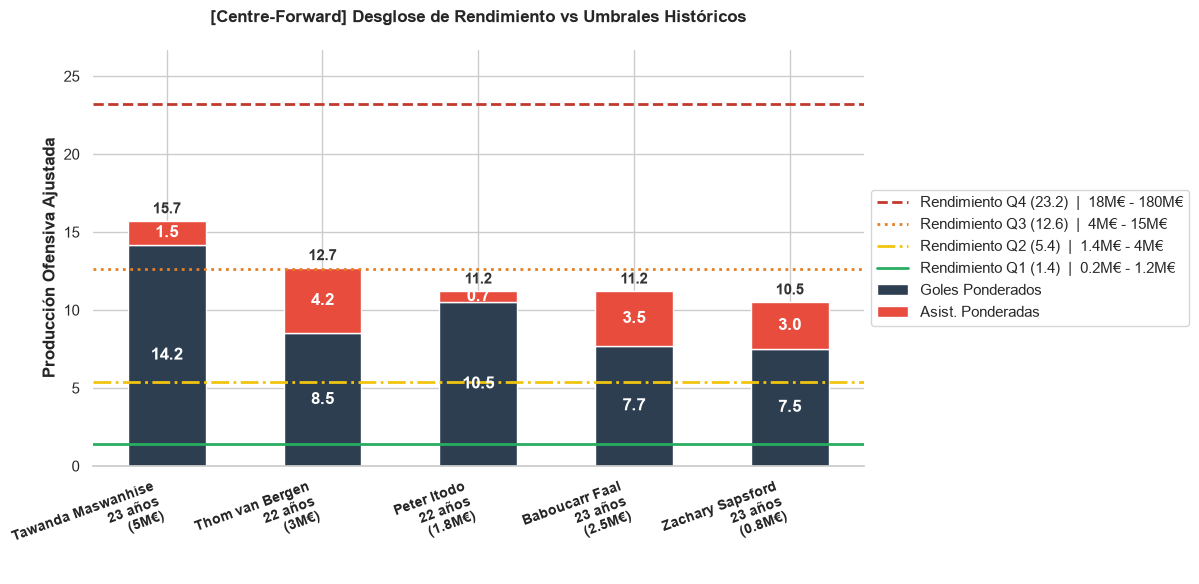

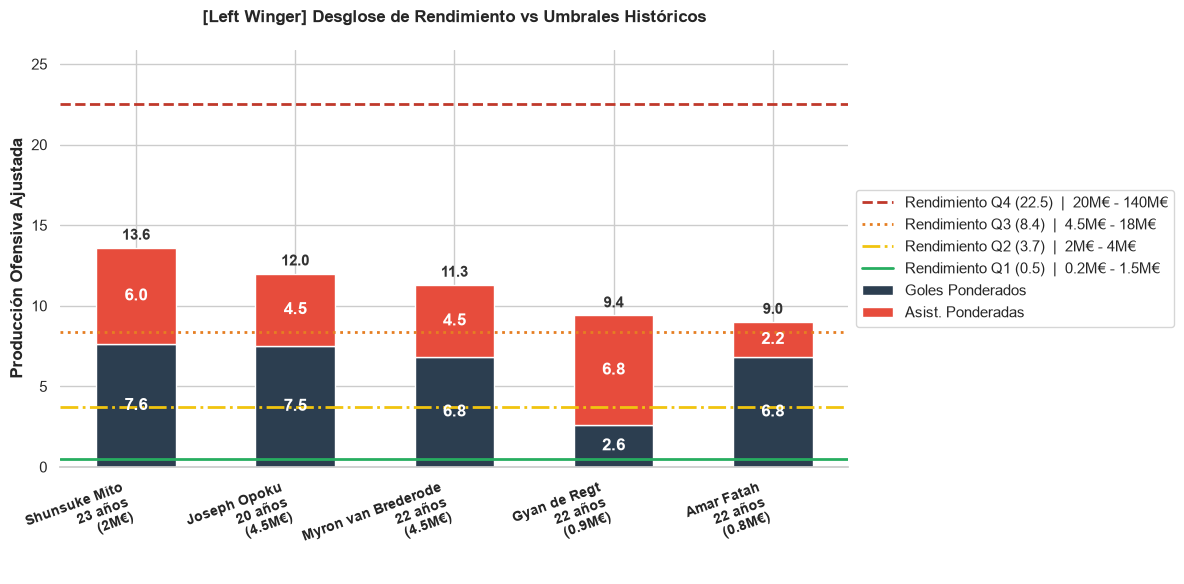

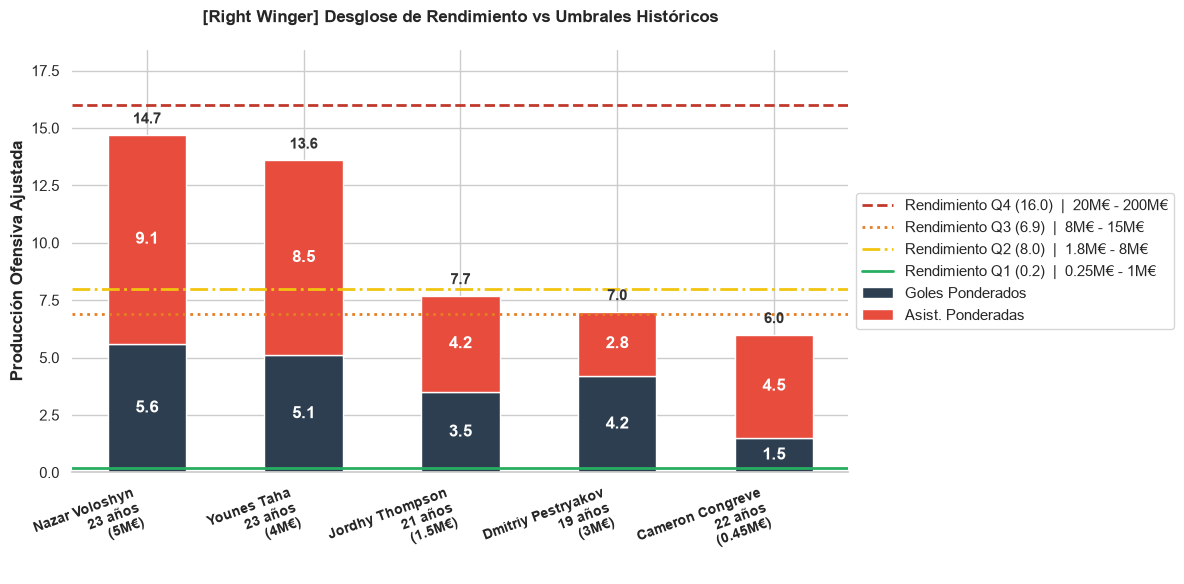

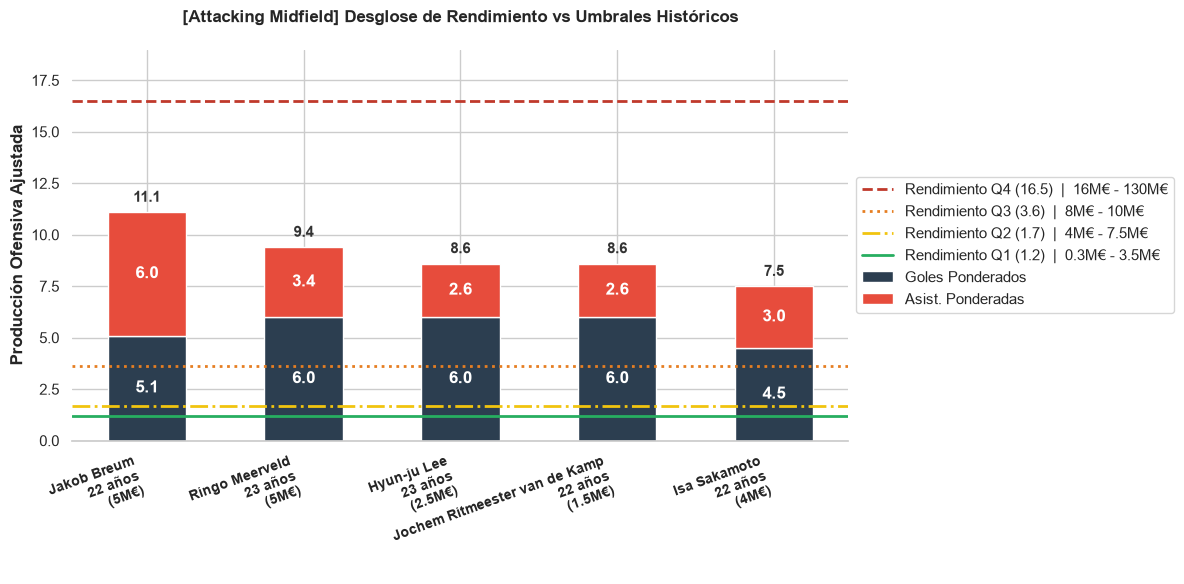

In [117]:
for demarcacion in demarcaciones_ofensivas:
    
    display(HTML(f"<h2 style='color:#2c3e50; border-bottom: 2px solid #2c3e50; margin-top: 40px; padding-bottom:5px;'>Análisis de Mercado: {demarcacion}</h2>"))
    
    # SOLO CLUBES HISTÓRICOS ININTERRUMPIDOS
    laliga_pos = df_1[(df_1['liga'] == liga_objetivo) & 
                      (df_1['sub_posicion'] == demarcacion) & 
                      (df_1['club'].isin(clubes_historicos_laliga))].copy()
    
    if laliga_pos.empty:
        print(f"No hay suficientes datos en La Liga para la posición {demarcacion}.")
        continue
        
    laliga_pos['produccion_total'] = laliga_pos['goles_25_26'] + laliga_pos['asis_25_26']
    
    # Dividir en 4 Cuartiles por PRECIO dinámicamente 
    etiquetas_cuartiles = ['Q1 (Bajo Coste)', 'Q2 (Media-Baja)', 'Q3 (Media-Alta)', 'Q4 (Élite)']
    laliga_pos['Cuartil_Mercado'] = pd.qcut(laliga_pos['valor_mercado'].rank(method='first'), q=4, labels=etiquetas_cuartiles)
    
    # Extraer Rangos de Precio y Estadísticas Medias 
    resumen_cuartiles = laliga_pos.groupby('Cuartil_Mercado', observed=False).agg(
        Precio_Min=('valor_mercado', 'min'),
        Precio_Max=('valor_mercado', 'max'),
        Goles_Media=('goles_25_26', 'mean'),
        Asis_Media=('asis_25_26', 'mean'),
        Prod_Media=('produccion_total', 'mean')
    ).reset_index()
    
    resumen_cuartiles['Rango Precio'] = resumen_cuartiles.apply(lambda x: f"{x['Precio_Min']/1e6:g}M€ - {x['Precio_Max']/1e6:g}M€", axis=1)
    resumen_cuartiles[['Goles_Media', 'Asis_Media', 'Prod_Media']] = resumen_cuartiles[['Goles_Media', 'Asis_Media', 'Prod_Media']].round(1)

    
    #  Ubicar gangas en los Cuartiles
    talentos = df_shortlist[df_shortlist['Demarcación'] == demarcacion].copy()
    if talentos.empty:
        print(f"No se encontraron talentos Sub-23 viables en la posición {demarcacion} por debajo de 5M€.\n")
        continue
        
    # Extraemos las métricas medias y los rangos
    prod_q4 = resumen_cuartiles.loc[3, 'Prod_Media']
    prod_q3 = resumen_cuartiles.loc[2, 'Prod_Media']
    prod_q2 = resumen_cuartiles.loc[1, 'Prod_Media']
    prod_q1 = resumen_cuartiles.loc[0, 'Prod_Media']
    
    rango_q4 = resumen_cuartiles.loc[3, 'Rango Precio']
    rango_q3 = resumen_cuartiles.loc[2, 'Rango Precio']
    rango_q2 = resumen_cuartiles.loc[1, 'Rango Precio']
    rango_q1 = resumen_cuartiles.loc[0, 'Rango Precio']
    
    # ORDENAMIENTO INTELIGENTE
    umbrales = [
        (prod_q4, 'Rinde como Q4 Élite'),
        (prod_q3, 'Rinde como Q3 (Media-Alta)'),
        (prod_q2, 'Rinde como Q2 (Media-Baja)'),
        (prod_q1, 'Rinde como Q1 (Bajo Coste)')
    ]
    umbrales_ordenados = sorted(umbrales, key=lambda x: x[0], reverse=True)
    
    condiciones = [talentos['Produccion_Ajustada'] >= u[0] for u in umbrales_ordenados]
    etiquetas_rendimiento = [u[1] for u in umbrales_ordenados]
    
    talentos['Rendimiento_Equivalente'] = np.select(condiciones, etiquetas_rendimiento, default='Bajo nivel')
    
    top_gangas = talentos.sort_values(by='Produccion_Ajustada', ascending=False).head(5)
    
    # Barras Apiladas con Rangos
    fig, ax = plt.subplots(figsize=(12, 6)) #ANCHURA AUMENTADA PARA QUE RESPIRE
    x = np.arange(len(top_gangas))
    
    barras_goles = ax.bar(x, top_gangas['Goles_Ajustados'], width=0.5, color='#2c3e50', label='Goles Ponderados')
    barras_asis = ax.bar(x, top_gangas['Asist_Ajustadas'], width=0.5, bottom=top_gangas['Goles_Ajustados'], color='#e74c3c', label='Asist. Ponderadas')
    
    ax.axhline(y=prod_q4, color='#c0392b', linestyle='--', linewidth=2, label=f'Rendimiento Q4 ({prod_q4})  |  {rango_q4}')
    ax.axhline(y=prod_q3, color='#e67e22', linestyle=':', linewidth=2, label=f'Rendimiento Q3 ({prod_q3})  |  {rango_q3}')
    ax.axhline(y=prod_q2, color='#f1c40f', linestyle='-.', linewidth=2, label=f'Rendimiento Q2 ({prod_q2})  |  {rango_q2}')
    ax.axhline(y=prod_q1, color='#27ae60', linestyle='-', linewidth=2, label=f'Rendimiento Q1 ({prod_q1})  |  {rango_q1}')
    
    ax.set_ylabel('Producción Ofensiva Ajustada', fontweight='bold')
    ax.set_title(f'[{demarcacion}] Desglose de Rendimiento vs Umbrales Históricos', fontweight='bold', pad=20)
    ax.set_xticks(x)
    #Evitar solapamientos nombres
    
    # Creamos una lista combinando el Nombre y el Valor de Mercado (en millones)
    etiquetas_x = [f"{nombre}\n{int(edad)} años\n({precio/1e6:g}M€)" for nombre,edad, precio in zip(top_gangas['Nombre'], top_gangas['Edad'], top_gangas['Valor Mercado (€)'])]
    
    #Asignamos la nueva lista al eje X
    ax.set_xticklabels(etiquetas_x, fontsize=10, fontweight='bold', rotation=20, ha='right')    
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    ax.bar_label(barras_goles, fmt=lambda val: f'{val:.1f}' if val > 0 else '', label_type='center', color='white', fontweight='bold')
    ax.bar_label(barras_asis, fmt=lambda val: f'{val:.1f}' if val > 0 else '', label_type='center', color='white', fontweight='bold')
    
    for i, total in enumerate(top_gangas['Produccion_Ajustada']):
        ax.text(i, total + 0.5, f"{total:.1f}", ha='center', fontweight='bold', color='#333333', fontsize=11)
    
    limite_superior = max(top_gangas['Produccion_Ajustada'].max(), umbrales_ordenados[0][0])
    ax.set_ylim(0, limite_superior + (limite_superior * 0.15))
    
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()